# Modelagem e Segmentação

**Dataset de entrada:** `data/processed/master.csv` (48.895 linhas x 14 colunas, sendo 2 coordenadas geograficas e 12 variaveis explicativas, ja limpo e sem nulos).

- Aplicar **K-Means**, **DBSCAN** e **HDBSCAN** sobre a `base padronizada`, 

- determinar o **K ideal** e os **hiperparametros** otimos de densidade, 

- diagnosticar a **estrutura topologica** aplicando Redução de Dimensionalidade com algorítmos `PCA (Linear)` e `UMAP (Não Linear)`, 

- Identificar os `Perfis comerciais` e sua **distribuição geoespacial**

---

### Sumario

| Secao | Topico |
| :--- | :--- |
| [1.0](#1.0) | Configuracao do Ambiente e Carregamento dos Dados |
| [2.0](#2.0) | Preparacao da Base de Perfilamento, Tratamento de Outliers e Padronizacao |
| [3.0](#3.0) | Modelagem Particional com K-Means e Diagnostico Topologico |
| [4.0](#4.0) | Modelagem Baseada em Densidade: DBSCAN vs. HDBSCAN |
| [5.0](#5.0) | Perfilamento Final e Mapeamento Geoespacial (HDBSCAN) |

___

## 1.0 Configuracao do Ambiente e Carregamento dos Dados

In [1]:
import os
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, DBSCAN
import hdbscan
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import umap
import plotly.express as px
import plotly.graph_objects as go
sys.path.append(os.path.abspath('..'))
import geopandas as gpd
%load_ext autoreload
%autoreload 2
import contextily as ctx
from shapely.geometry import Point

from utils_2 import (
    plot_elbow_comparativo,
    plot_metricas_validacao,
    plot_distribuicao_clusters,
    plot_clusters_2d_plotly,
    avaliar_grade_dbscan,
    plot_metricas_dbscan,
    avaliar_grade_hdbscan,
    plot_metricas_hdbscan,
    gerar_perfil_clusters,
    plot_mapa_clusters_nyc,
)

warnings.filterwarnings('ignore')

In [2]:
# Carregamento do dataset processado (

nome_arquivo = 'master.csv'

DIR_ATUAL = os.getcwd()

DIR_ARQ = os.path.join(DIR_ATUAL, '..', 'data', 'processed', nome_arquivo)

X = pd.read_csv(DIR_ARQ)

display(X.head(10))

X.info()

,latitude,longitude,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes_log
0,40.64749,-73.97237,1,365,5.010635,0.190620,1,0,0,0,0.111287,5.010635,7.692113,3.780933
1,40.75362,-73.98377,2,355,5.420535,0.322083,0,1,0,0,0.004709,5.420535,6.566672,4.782653
2,40.80902,-73.94190,1,365,5.017280,0.000000,0,1,0,0,0.067112,6.111467,5.902633,0.000000
3,40.68514,-73.95976,2,194,4.499810,1.729884,1,0,0,0,0.077273,4.499810,5.273000,4.080747
4,40.79851,-73.94399,2,0,4.394449,0.095310,0,1,0,0,0.058001,6.685861,0.000000,4.510850
5,40.74767,-73.97500,2,129,5.303305,0.463734,0,1,0,0,0.014730,6.398595,4.867534,4.839638
6,40.68688,-73.95596,1,0,4.110874,0.336472,1,0,0,0,0.077011,7.901377,0.000000,4.816239
7,40.76489,-73.98493,1,220,4.382027,1.497388,0,1,0,0,0.006914,5.068904,5.398163,4.827668
8,40.80178,-73.96723,1,0,4.382027,0.688135,0,1,0,0,0.047439,5.068904,0.000000,4.789089
9,40.71344,-73.99037,2,188,5.017280,0.845868,0,1,0,0,0.044825,5.017280,6.624065,4.798272


<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           48895 non-null  float64
 1   longitude                          48895 non-null  float64
 2   room_type                          48895 non-null  int64  
 3   availability_365                   48895 non-null  int64  
 4   price_log                          48895 non-null  float64
 5   reviews_per_month_log              48895 non-null  float64
 6   neighbourhood_group_Brooklyn       48895 non-null  int64  
 7   neighbourhood_group_Manhattan      48895 non-null  int64  
 8   neighbourhood_group_Queens         48895 non-null  int64  
 9   neighbourhood_group_Staten Island  48895 non-null  int64  
 10  distancia_Times_Square             48895 non-null  float64
 11  custo_estadia_log                  48895 non-null  float64
 12  v

>
> Veja que para a futura **modelagem dos dados**, devemos: 
> 
> - Isolar as `Features Geográficas` 
>
> - Remover Outliers via **Clipping (1% de cada extremidade)**
>
> - **Padronizar** os dados para evitar distorções 

___

## 2.0 Preparacao da Base de Perfilamento, Tratamento de Outliers e Padronizacao

- **X_analise:** as colunas em escala log (`_log`) sao revertidas com `np.expm1` para obter valores na escala original (US$, dias, etc.), facilitando a interpretação

-  **X_geo e X_modelo:** as coordenadas geograficas sao separadas em `X_geo`. As 12 features explicativas permanecem em `X_modelo`.

- **X_tratado:** aplica-se clipping nos quantis 0.01 e 0.99 para conter outliers extremos, seguido de `RobustScaler` para normalizar via mediana e IQR.

In [3]:
# X_analise: base em escala real para o perfilamento 

X_analise = X.copy()

# Colunas previamente transformadas em log, serão revertidas para o valor original para o X_analise ser usado nos perfis

cols_log = [
    'price_log',
    'reviews_per_month_log',
    'custo_estadia_log',
    'volume_oferta_dias_anfitriao_log',
    'taxa_reviews_mes_log',
]

for col in cols_log:
    nome_original = col.replace('_log', '')
    X_analise[nome_original] = np.expm1(X_analise[col])
    X_analise = X_analise.drop(columns=[col])

print("X_análise:\n")

X_analise.info()

# Separação das coordenadas geograficas para visualizacao futura

X_geo = X[['latitude', 'longitude']].copy()
X_modelo = X.drop(columns=['latitude', 'longitude'])

# Clipping + RobustScaler sobre as 12 features explicativas

limite_inferior = X_modelo.quantile(0.01)
limite_superior = X_modelo.quantile(0.99)
X_clipado = X_modelo.clip(lower=limite_inferior, upper=limite_superior, axis=1)

padronizador = RobustScaler().fit(X_clipado)
X_tratado = pd.DataFrame(
    padronizador.transform(X_clipado),
    columns=X_clipado.columns,
    index=X_clipado.index
)

print("\n X_tratado: \n")

display(X_tratado.head(10))

X_análise:

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           48895 non-null  float64
 1   longitude                          48895 non-null  float64
 2   room_type                          48895 non-null  int64  
 3   availability_365                   48895 non-null  int64  
 4   neighbourhood_group_Brooklyn       48895 non-null  int64  
 5   neighbourhood_group_Manhattan      48895 non-null  int64  
 6   neighbourhood_group_Queens         48895 non-null  int64  
 7   neighbourhood_group_Staten Island  48895 non-null  int64  
 8   distancia_Times_Square             48895 non-null  float64
 9   price                              48895 non-null  float64
 10  reviews_per_month                  48895 non-null  float64
 11  custo_estadia                      48895 non-null  fl

,room_type,availability_365,price_log,reviews_per_month_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square,custo_estadia_log,volume_oferta_dias_anfitriao_log,taxa_reviews_mes_log
0,-1.0,1.409692,0.366389,-0.136688,1.0,0.0,0.0,0.0,0.841965,-0.412629,0.621053,0.379815
1,0.0,1.365639,0.810971,0.008005,0.0,1.0,0.0,0.0,-1.096765,-0.169783,0.426778,0.664264
2,-1.0,1.409692,0.373596,-0.346491,0.0,1.0,0.0,0.0,0.033567,0.239563,0.312150,-1.018622
3,0.0,0.656388,-0.187659,1.557475,1.0,0.0,0.0,0.0,0.219514,-0.715270,0.203461,0.490706
4,0.0,-0.198238,-0.301934,-0.241589,0.0,1.0,0.0,0.0,-0.133155,0.579865,-0.706773,0.649786
5,0.0,0.370044,0.683822,0.163910,0.0,1.0,0.0,0.0,-0.925015,0.409673,0.133469,0.664264
6,-1.0,-0.198238,-0.609503,0.023841,1.0,0.0,0.0,0.0,0.214715,1.300002,-0.706773,0.664264
7,-1.0,0.770925,-0.315408,1.301583,0.0,1.0,0.0,0.0,-1.068046,-0.378108,0.225067,0.664264
8,-1.0,-0.198238,-0.315408,0.410892,0.0,1.0,0.0,0.0,-0.326437,-0.378108,-0.706773,0.664264
9,0.0,0.629956,0.373596,0.584499,0.0,1.0,0.0,0.0,-0.374270,-0.408693,0.436685,0.664264


___

## 3.0 Modelagem Particional com K-Means

### 3.1 Fundamentos Matematicos

K-Means e um algoritmo que separa um conjunto de `n` pontos em `k` grupos/clusters com pontos semelhantes entre si.

Cada grupo (cluster) possui um **centroide**, que e atribuido como o centro de cada cluster. Ele **nao necessariamente e um ponto real do dataset**.

#### Formula do centroide

$$
\mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i
$$

#### Distancia Euclidiana

$$
d(x, \mu) = \sqrt{\sum_{j=1}^{d} (x_j - \mu_j)^2}
$$

Na pratica, o K-Means usa a **distancia euclidiana ao quadrado** (sem a raiz):

$$
\|x - \mu\|^2 = \sum_{j=1}^{d} (x_j - \mu_j)^2
$$
>
> Por isso, e extremamente importante **padronizar os dados de entrada**. Features com escalas diferentes dominariam o calculo da distancia.
>

### 3.2 Ciclo do Algoritmo

O algoritmo e iterativo e alterna entre atribuicao e recalculo dos centros:

**1) Inicializar centros aleatorios (Forgy / K-Means++)**

O metodo de Forgy sorteia `k` pontos reais do dataset como centros iniciais. Uma alternativa melhor e o **K-Means++**, que escolhe centros espalhados proporcionalmente a **distancia ao quadrado ao centro mais proximo** ja escolhido.

**2) Atribuir cada ponto ao centroide mais proximo**

$$
\text{cluster}(x_i) = \arg\min_{k=1,\dots,K} \|x_i - \mu_k\|^2
$$

**3) Recalcular os centroides**

$$
\mu_k \leftarrow \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i
$$

**4) Repetir ate convergir**

Repete-se os passos 2 e 3 ate que as atribuicoes nao mudem mais, os centroides se movam menos que uma tolerancia `epsilon`, ou atinja-se um numero maximo de iteracoes.

> Cada passo nunca aumenta a inercia, entao o algoritmo converge — mas para um **minimo local**. Por isso e comum rodar varias inicializacoes (`n_init`) e ficar com a de menor inercia.

### 3.3 Metricas de Avaliacao

Como nao ha rotulos verdadeiros, avaliamos a qualidade geometrica da particao: **coesao** (pontos perto do seu centroide) e **separacao** (clusters longe uns dos outros).

#### Inertia (WCSS — Within-Cluster Sum of Squares)

$$
\text{Inertia} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2
$$

- **Menor e melhor** (e o objetivo que o K-Means minimiza).
- **Nao serve para comparar `k` diferentes**, pois sempre diminui quando `k` aumenta.
- Uso classico: **metodo do cotovelo (elbow)** — plotar inercia vs. `k` e procurar o "joelho" da curva.

#### Silhouette

Para cada ponto `i`:
- `a(i)` = distancia media aos outros pontos do **mesmo cluster** (coesao)
- `b(i)` = distancia media aos pontos do **cluster vizinho mais proximo** (separacao)

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i),\, b(i))} \in [-1, 1]
$$

- **Maior e melhor** (perto de +1 = ponto bem dentro do seu cluster).
- Custo `O(n^2)` — caro para `n` grande.

#### Davies-Bouldin

$$
\text{DB} = \frac{1}{K} \sum_{i=1}^{K} \max_{j \neq i} \frac{s_i + s_j}{d(\mu_i,\, \mu_j)}
$$

- **Menor e melhor** (0 e o ideal).

#### Calinski-Harabasz

$$
\text{CH} = \frac{\operatorname{tr}(B_K)/(K-1)}{\operatorname{tr}(W_K)/(n-K)}
$$

- **Maior e melhor** (clusters compactos e bem separados).
- Custo `O(n)`, relativamente barato.

| Metrica | O que mede | Direcao | Compara `k`? | Custo |
|---|---|---|---|---|
| **Inertia** | coesao interna (SSE) | menor melhor | nao | `O(nKd)` |
| **Silhouette** | coesao + separacao | maior melhor | sim | `O(n^2)` |
| **Davies-Bouldin** | dispersao / separacao | menor melhor | sim | `O(nKd + K^2d)` |
| **Calinski-Harabasz** | var. entre / var. interna | maior melhor | sim | `O(nKd)` |

### 3.4 Determinacao do K Ideal (Metodo Elbow e Metricas)

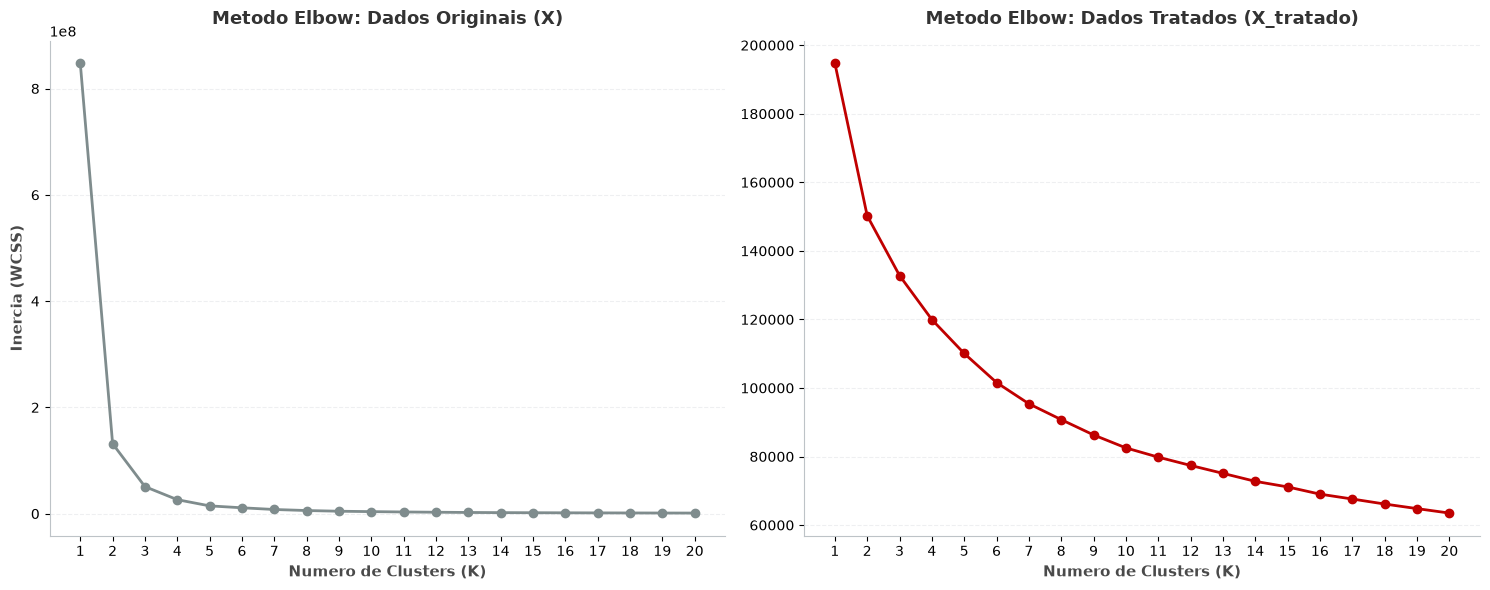

In [4]:
# Metodo Elbow: K=1 ate 20 para X_modelo (sem escalonamento) e X_tratado (escalonado)

k_valores = list(range(1, 21))
inercias_x = []
inercias_x_tratado = []

for k in k_valores:
    modelo_km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                       max_iter=300, random_state=10)

    modelo_km.fit(X_modelo)
    inercias_x.append(modelo_km.inertia_)

    modelo_km.fit(X_tratado)
    inercias_x_tratado.append(modelo_km.inertia_)

plot_elbow_comparativo(k_valores, inercias_x, inercias_x_tratado)


> Com os **dados originais sem tratamento**, a Inercia aparece na casa de `10^8`, muito alto,  e possui **grandes oscilacoes** como é possível verificar entre `K=1 e K=3`
>
> Para **X_tratado** (RobustScaler + Clipping), os dados decrescem de maneira bem mais uniforme, reduzindo a inercia associada para a casa do `10^5`
>
>  O **range de K entre 7 e 12 apresenta ponto de inflexao visivel**, com `menor reducao marginal e maior estabilidade`,mas devemos buscar mais métricas pra encontrar o melhor K

,K,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Tamanho_dos_Clusters
0,2,150237.76,0.20,1.77,14488.99,"{0: 22908, 1: 25987}"
1,3,132805.62,0.17,1.88,11404.04,"{0: 17341, 1: 17575, 2: 13979}"
2,4,119945.53,0.16,1.82,10164.95,"{0: 9558, 1: 13803, 2: 12164, 3: 13370}"
3,5,110072.07,0.17,1.71,9403.74,"{0: 9230, 1: 13221, 2: 9782, 3: 6757, 4: 9905}"
4,6,101585.18,0.18,1.65,8968.21,"{0: 9064, 1: 11135, 2: 3490, 3: 9155, 4: 9317,..."
5,7,95384.26,0.18,1.62,8488.90,"{0: 8996, 1: 9023, 2: 7410, 3: 5620, 4: 5875, ..."
6,8,90762.81,0.18,1.57,8002.13,"{0: 5371, 1: 4726, 2: 3091, 3: 8732, 4: 7493, ..."
7,9,86300.47,0.18,1.60,7679.74,"{0: 2911, 1: 5188, 2: 4767, 3: 4701, 4: 6222, ..."
8,10,82516.50,0.18,1.57,7388.41,"{0: 3921, 1: 6586, 2: 6453, 3: 4389, 4: 4329, ..."


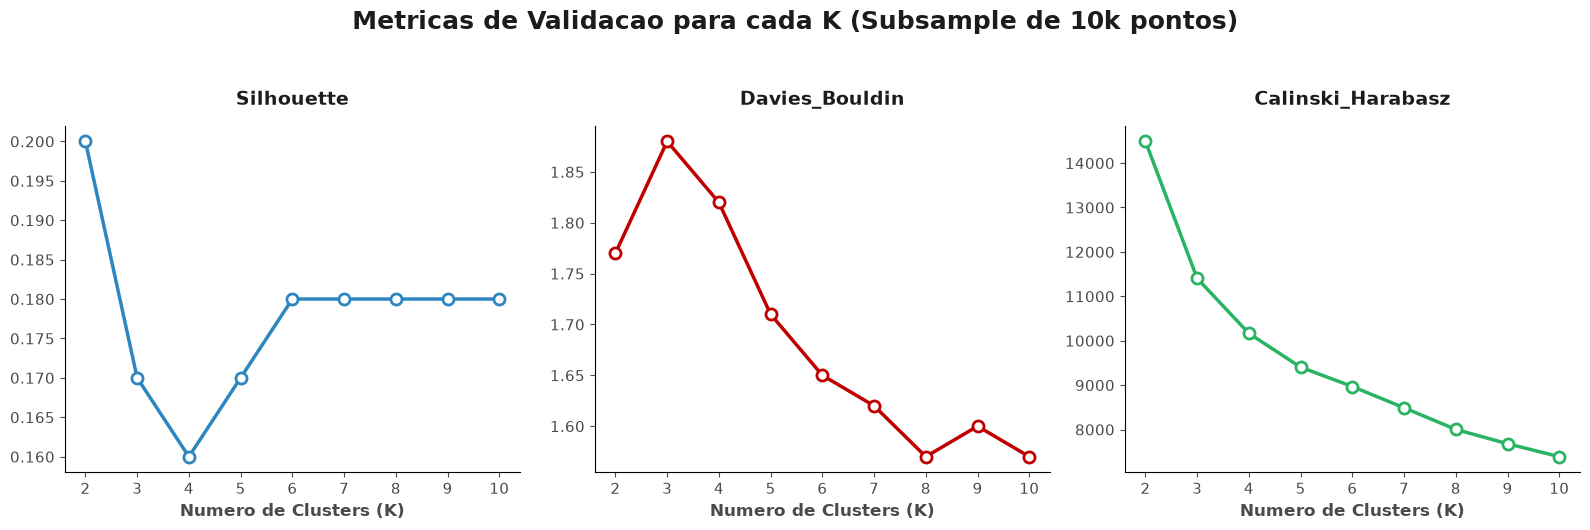

In [5]:
# Metricas de validacao: K=2 ate 10 com subsample de 10k pontos

k_valores = range(2, 11)
resultados_metricas = []

for k in k_valores:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, # Método Kmeans ++
                max_iter=300, random_state=10)
    labels = km.fit_predict(X_tratado)

    valores_unicos, contagens = np.unique(labels, return_counts=True)
    distribuicao_tamanhos = {int(c): int(q) for c, q in zip(valores_unicos, contagens)}

    resultados_metricas.append({
        'K': k,
        'Inertia': km.inertia_,
        'Silhouette': silhouette_score(X_tratado, labels, sample_size=10000, random_state=10),
        'Davies_Bouldin': davies_bouldin_score(X_tratado, labels),
        'Calinski_Harabasz': calinski_harabasz_score(X_tratado, labels),
        'Tamanho_dos_Clusters': distribuicao_tamanhos,
    })

df_resultados = pd.DataFrame(resultados_metricas)
colunas_float = ['Inertia', 'Silhouette', 'Davies_Bouldin', 'Calinski_Harabasz']
df_resultados[colunas_float] = df_resultados[colunas_float].round(2)
display(df_resultados)

plot_metricas_validacao(df_resultados)

> * **Observacao Principal:** A metrica de Davies-Bouldin atinge seu menor valor, pico, em **K=8** (1.57), indicando a melhor relacao entre dispersao interna e separacao entre clusters. 
>
> Em **K=8**, ao mesmo tempo, A `Silhouette se mantém estável na faixa dos 0.180` e o **Calinski-Harabasz mantem tendencia decrescente controlada**.
>
>  Nesse sentido, **K=8 é selecionado como o número ideal de clusters**, equilibrando a `qualidade geometrica da particao (DB ótimo)` com a estabilidade das demais metricas.

### 3.5 Ajuste Final (K=8) e Distribuicao de Volume

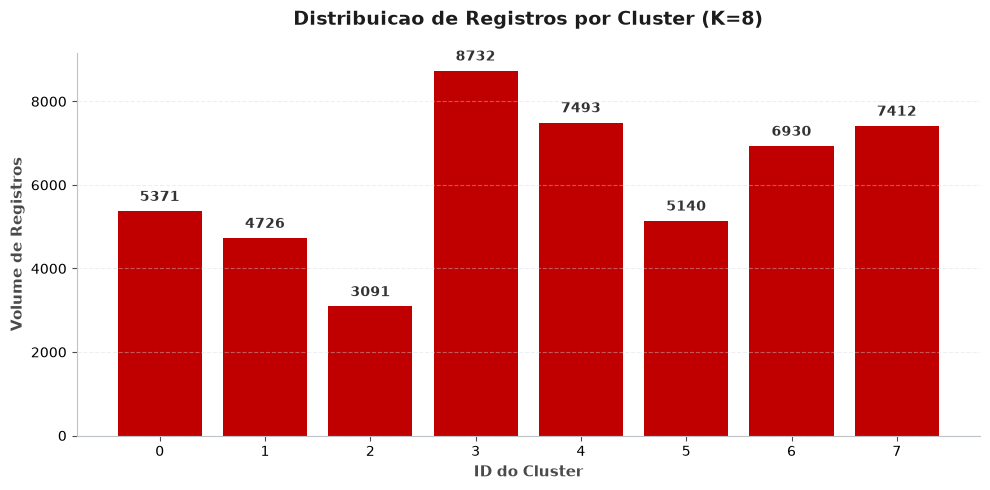

In [6]:
# Ajuste do modelo final com K=8 (K-Means++)

km_final = KMeans(n_clusters=8, init='k-means++', n_init=10,
                  max_iter=300, random_state=10)
labels_k8 = km_final.fit_predict(X_tratado)

# Distribuicao de volume por cluster
plot_distribuicao_clusters(
    labels_k8,
    titulo='Distribuicao de Registros por Cluster (K=8)'
)

> - Os **8 clusters apresentam distribuicao parcialmente equilibrada**, com tamanhos variando entre aproximadamente `3k e 9k pontos`.
>
> A princípio, **numa análise inicial**, a `ausencia de clusters extremamente desbalanceados indica que o K-Means conseguiu segmentar a base de forma razoavel`.
>
> Nesse sentido, como estamos **trabalhando com clusterização** devemos analisar a como a `Red de Dimensionalidade` impacta na segmentação e interpretabilidade dos pontos.

### 3.6 Reducao de Dimensionalidade e Diagnostico Topologico do K-Means (PCA e UMAP)

- O **PCA (Linear) com 2 componentes** retém **51.33%** da variancia total **[33.89 + 17.44]**.

- A `Projecao linear (PCA)` e `nao-linear (UMAP)` permitem diagnosticar se os cortes do K-Means
respeitam a estrutura dos dados.



In [7]:
# Paleta de cores corporativa para K=8
CORES_CLUSTERS = {
    0: '#7F8C8D', 1: '#C00000', 2: '#007006', 3: '#A6FF00',
    4: '#2E86C1', 5: '#F39C12', 6: '#8E44AD', 7: '#34495E',
}

# PCA: 2 componentes (soma = 51.33% da variancia explicada)
pca = PCA(n_components=2, random_state=10)
X_pca = pca.fit_transform(X_tratado)

var_explicada = pca.explained_variance_ratio_
print(f'Variancia explicada individual: {np.round(var_explicada * 100, 2)}%')
print(f'Variancia total mantida (2 comp.): {var_explicada.sum() * 100:.2f}%')

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Cluster'] = labels_k8

# UMAP: 2 componentes para projecao topologica nao-linear
redutor_umap = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=10)
X_umap = redutor_umap.fit_transform(X_tratado)

df_umap = pd.DataFrame(X_umap, columns=['UMAP1', 'UMAP2'])
df_umap['Cluster'] = labels_k8

Variancia explicada individual: [33.89 17.44]%
Variancia total mantida (2 comp.): 51.33%


In [8]:
# Projecao 2D via PCA (componentes principais lineares)
plot_clusters_2d_plotly(
    df_pca, col_x='PC1', col_y='PC2',
    mapa_cores=CORES_CLUSTERS,
    titulo='Projecao 2D (PCA): Clusters do K-Means (K=8)'
)

>
> Com apenas **51.33% da variancia retida em 2D**, o **PCA mostra forte sobreposicao entre os clusters**, mostrando que a `clusterização ideal dos dados não segue um padrão linear de bases ortonormais.`
>
>  Nesse sentido, vamos analisar um algoritmo de **redução não lineares**, buscamos ainda validar a **hipótese de clusterização por geometria esférica como válida**.

In [9]:
# Projecao 2D via UMAP (estrutura topologica nao-linear)
plot_clusters_2d_plotly(
    df_umap, col_x='UMAP1', col_y='UMAP2',
    mapa_cores=CORES_CLUSTERS,
    titulo='Projecao 2D (UMAP): Clusters do K-Means (K=8)'
)


> O **UMAP revela ilhas nao-lineares** as quais o K-Means, por `impor fronteiras esfericas`, corta **artificialmente ao meio**. 
>
> Varios clusters apresentam **intersecções sobrepostas** que `não correspondem a agrupamentos naturais esperados para grupos de imóveis.`
>
> Mesmo com um algoritmo de **redução nao-linear**, o K-Means `não conseguiu capturar a topologia real dos dados`. 
>
> As entre **fronteiras e geometrias dos agrupamentos sao mais complexas** e exigem algoritmos baseados em `densidade (DBSCAN/HDBSCAN)`, de modo a respeitar a **geometria e identificar ruídos**

### 3.7 Perfilamento Preliminar dos Clusters (K-Means)

In [10]:
bairros_dummies = [
    'neighbourhood_group_Brooklyn',
    'neighbourhood_group_Manhattan',
    'neighbourhood_group_Queens',
    'neighbourhood_group_Staten Island',
]

X_analise['Cluster_KMeans'] = labels_k8
perfil_km, distritos_km = gerar_perfil_clusters(X_analise, 'Cluster_KMeans', bairros_dummies)

display(perfil_km)
display(distritos_km)

,Preco_Mediano,Custo_Estadia_Mediano,Distancia_Times_Square_Mediana,Reviews_Mes_Mediano,Taxa_Reviews_Mediana,Disponibilidade_Mediana,Volume_Oferta_Host,room_type_Moda,Tamanho_do_Cluster,Perc_Base (%)
Cluster_KMeans,,,,,,,,,,
0,80.0,165.0,0.05,0.15,16.67,0.0,0.0,1,5371,10.98
1,222.0,4210.5,0.03,0.08,2.27,311.0,1013.0,2,4726,9.67
2,75.0,135.0,0.18,1.26,10.75,170.0,283.0,1,3091,6.32
3,150.0,500.0,0.08,0.39,21.64,20.0,22.0,2,8732,17.86
4,60.0,149.0,0.08,0.09,12.04,0.0,0.0,1,7493,15.32
5,150.0,300.0,0.04,2.59,15.70,189.0,247.0,2,5140,10.51
6,185.0,596.0,0.03,0.13,18.42,0.0,0.0,2,6930,14.17
7,65.0,130.0,0.09,1.58,15.98,249.0,360.0,1,7412,15.16


,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island
Cluster_KMeans,,,,
0,0.0,98.6,1.4,0.0
1,8.6,88.6,2.4,0.1
2,7.8,0.1,64.3,11.4
3,92.4,0.5,6.0,0.1
4,83.6,0.1,14.1,0.1
5,1.6,93.0,5.2,0.0
6,0.0,97.7,2.3,0.0
7,68.0,7.8,20.0,0.0


> ### Perfis Preliminares ( K-Means ) - Baseados em Partição
>
> * **Observacao Principal:** O K-Means segmentou a base em 8 grupos com perfis distintos de preco, localizacao e disponibilidade. Porem, clusters como 0, 4 e 6 concentram-se quase exclusivamente em Manhattan (98%+), sugerindo que o algoritmo esta essencialmente recortando o espaco por densidade populacional e nao por perfil de negocio.
> * **Impacto Metodologico:** A proxima secao introduz algoritmos baseados em densidade (DBSCAN e HDBSCAN) para respeitar a topologia real revelada pelo UMAP, isolar outliers como ruido estruturado e produzir segmentos de mercado mais acionaveis comercialmente.

___

## 4.0 Modelagem Baseada em Densidade: DBSCAN vs. HDBSCAN

>
- **Algoritmos baseados em centroides (K-Means) assumem clusters esfericos e exigem que o numero de grupos seja especificado a priori**.

-  **DBSCAN** e **HDBSCAN** operam sob o paradigma de `densidade`: identificam **regioes de alta densidade separadas por regioes de baixa densidade**,
 adaptando-se a geometria real dos dados e isolando automaticamente pontos anomalos como **ruido (label = -1)**.

### 4.1 Modelagem com DBSCAN

Iniciando varredura de hiperparametros do DBSCAN...

Testado: eps=0.3  | min_samples=15  -> Clusters: 48 | Ruido: 72.0%
Testado: eps=0.3  | min_samples=30  -> Clusters: 22 | Ruido: 78.4%
Testado: eps=0.3  | min_samples=50  -> Clusters: 15 | Ruido: 84.3%
Testado: eps=0.3  | min_samples=100 -> Clusters: 10 | Ruido: 94.0%
Testado: eps=0.5  | min_samples=15  -> Clusters: 50 | Ruido: 25.7%
Testado: eps=0.5  | min_samples=30  -> Clusters: 21 | Ruido: 39.7%
Testado: eps=0.5  | min_samples=50  -> Clusters: 21 | Ruido: 51.3%
Testado: eps=0.5  | min_samples=100 -> Clusters: 12 | Ruido: 65.1%
Testado: eps=0.8  | min_samples=15  -> Clusters: 23 | Ruido: 3.2%
Testado: eps=0.8  | min_samples=30  -> Clusters: 16 | Ruido: 6.5%
Testado: eps=0.8  | min_samples=50  -> Clusters: 9  | Ruido: 10.2%
Testado: eps=0.8  | min_samples=100 -> Clusters: 6  | Ruido: 17.6%
Testado: eps=1.0  | min_samples=15  -> Clusters: 10 | Ruido: 1.0%
Testado: eps=1.0  | min_samples=30  -> Clusters: 10 | Ruido: 2.0%
Testado: eps=

,eps,min_samples,N_Clusters,%_Ruido,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,0.3,15,48,71.96,-0.264861,1.231260,321.602391
3,0.3,100,10,94.04,-0.322132,1.238704,302.241532
2,0.3,50,15,84.28,-0.256949,1.297521,506.811729
1,0.3,30,22,78.41,-0.229185,1.299569,508.794971
4,0.5,15,50,25.67,-0.096467,1.427520,676.211147
6,0.5,50,21,51.31,-0.088969,1.491949,1153.703761
7,0.5,100,12,65.12,-0.097408,1.497490,1471.217567
5,0.5,30,21,39.74,-0.033533,1.518216,1377.095221
8,0.8,15,23,3.24,0.014283,1.877748,1508.976562
9,0.8,30,16,6.46,0.035999,1.934074,2082.901291


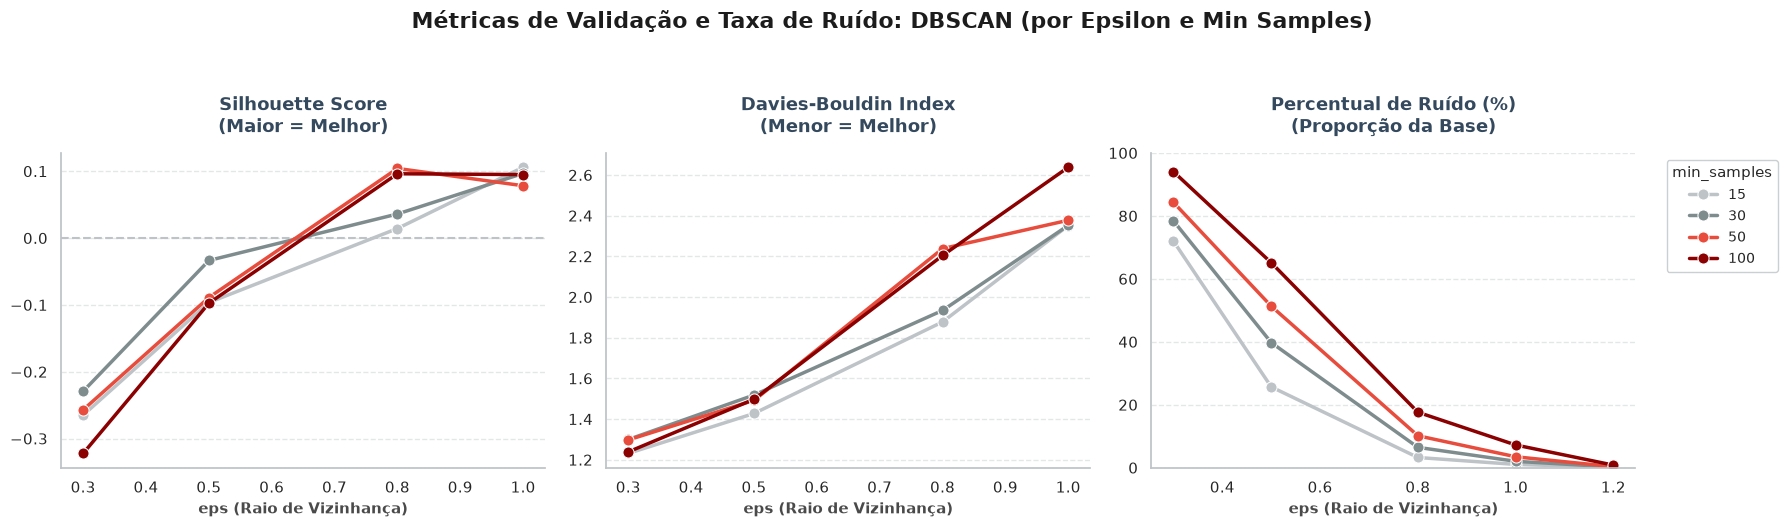

In [11]:
# Grade de Hiperparametros (20 combinacoes: 5 eps x 4 min_samples)

grade_eps = [0.3, 0.5, 0.8, 1.0, 1.2]
grade_min_samples = [15, 30, 50, 100]

df_dbscan = avaliar_grade_dbscan(X_tratado, grade_eps, grade_min_samples)

display(df_dbscan.sort_values(by='Davies_Bouldin').head(10))
plot_metricas_dbscan(df_dbscan)


> ### Limitações Estruturais do DBSCAN - Densidade Fixa
>
> A busca de hiperparâmetros (grid search) e os gráficos de validação revelam um **impasse estrutural** neste conjunto de dados. 
>
> Não existe uma combinação ótima de `eps` e `min_samples` que resolva o problema, o que é evidenciado visualmente por alguns fatores
>
> Visão geral: **Não existe um corte ótimo entre Ruído x DB:**
>
> -  **`eps` muito baixo (ex: 0,3):** O algoritmo captura apenas os `epicentros hiperdensos, como Manhatan`. Visualmente, a taxa de ruído dispara para **72% a 94%**, descartando a maior parte da base. O Índice `Davies-Bouldin` até parece baixo **(~1.2)** aqui, mas é um **falso positivo:** ele está avaliando apenas pequenos aglomerados isolados.
>
> - **`eps` muito alto (ex: 1,0 ou 1,2):** Para tentar reduzir o ruído, aumentamos o raio. O `gráfico de ruído cai drasticamente para perto de 0%`. Contudo, o **Índice DB sobe vertiginosamente (chegando a ~2.6)**, indicando que os clusters se fundiram e o poder de separação foi totalmente perdido. O modelo passa a ver quase tudo como um único bloco.
>
>  Mesmo no **"melhor cenário"** (onde o Silhouette atinge seu pico com `eps=0.8` ou `1.0`), o valor mal passa de **0.1**. Na prática, um Silhouette tão próximo de zero indica que os pontos estão praticamente no limite entre os clusters, confirmando que `não há uma separação clara por distância absoluta.`
>
> **Nesse caso, o DBSCAN não apresenta boa capacidade de clusterização**


### 4.2 HDBSCAN - Densidade Variável

Iniciando varredura de hiperparametros do HDBSCAN...

Testado: min_cluster_size=50  | min_samples=15 -> Clusters: 17 | Ruido: 18.8%
Testado: min_cluster_size=50  | min_samples=30 -> Clusters: 15 | Ruido: 17.4%
Testado: min_cluster_size=50  | min_samples=50 -> Clusters: 13 | Ruido: 21.0%
Testado: min_cluster_size=50  | min_samples=70 -> Clusters: 12 | Ruido: 27.4%
Testado: min_cluster_size=100 | min_samples=15 -> Clusters: 17 | Ruido: 18.8%
Testado: min_cluster_size=100 | min_samples=30 -> Clusters: 15 | Ruido: 17.4%
Testado: min_cluster_size=100 | min_samples=50 -> Clusters: 11 | Ruido: 21.3%
Testado: min_cluster_size=100 | min_samples=70 -> Clusters: 11 | Ruido: 26.6%
Testado: min_cluster_size=200 | min_samples=15 -> Clusters: 12 | Ruido: 8.4%
Testado: min_cluster_size=200 | min_samples=30 -> Clusters: 7  | Ruido: 7.8%
Testado: min_cluster_size=200 | min_samples=50 -> Clusters: 7  | Ruido: 11.3%
Testado: min_cluster_size=200 | min_samples=70 -> Clusters: 6  | Ruido: 14.9%
Testado: min

,min_cluster_size,min_samples,N_Clusters,%_Ruido,Silhouette,Davies_Bouldin,Calinski_Harabasz
3,50,70,12,27.45,-0.002401,1.937506,2111.514361
7,100,70,11,26.59,0.004867,2.002345,2359.191600
2,50,50,13,21.02,0.011187,2.012352,2249.486838
0,50,15,17,18.76,-0.017612,2.016761,2205.010064
4,100,15,17,18.76,-0.017612,2.016761,2205.010064
1,50,30,15,17.44,0.005685,2.018216,2187.709136
5,100,30,15,17.44,0.005685,2.018216,2187.709136
6,100,50,11,21.29,0.027072,2.086888,2618.951534
8,200,15,12,8.45,0.063875,2.280689,2923.254803
12,500,15,9,12.47,0.084701,2.438076,3644.810968


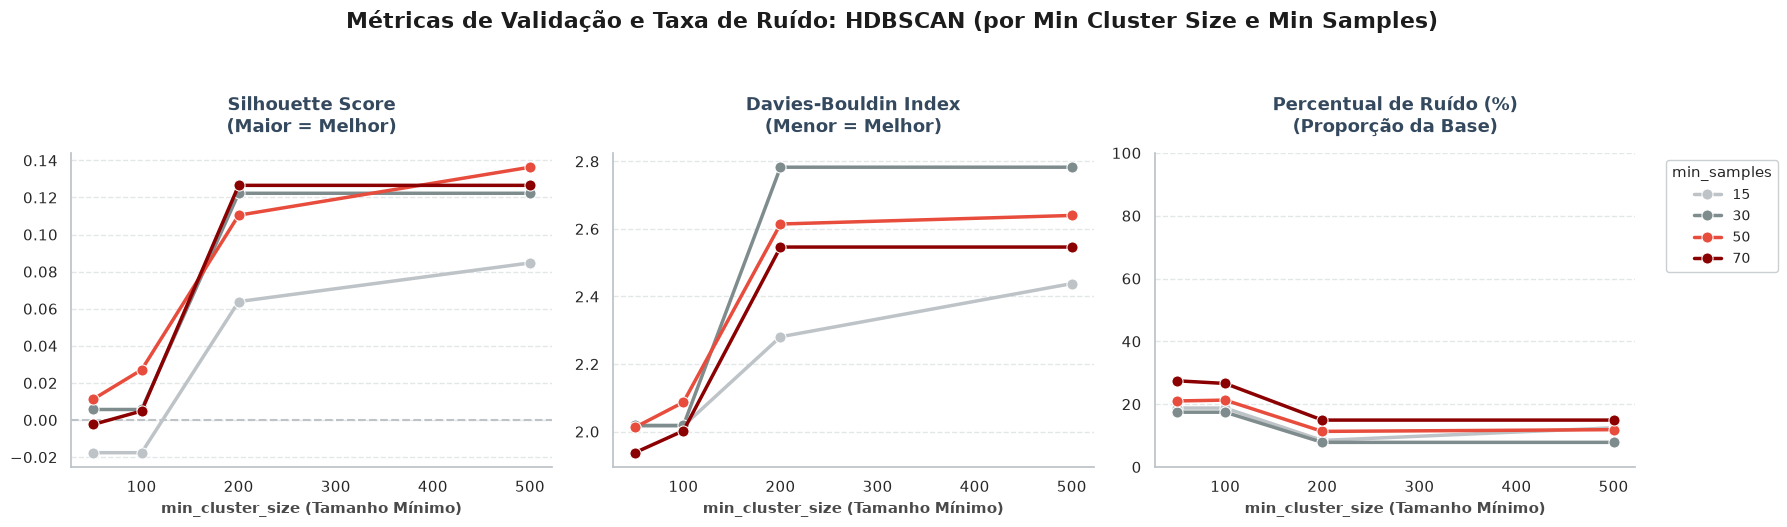

In [12]:
# Grade de Hiperparametros focada em densidade variavel
grade_min_cluster_size = [50, 100, 200, 500]
grade_min_samples = [15, 30, 50, 70]

df_hdbscan = avaliar_grade_hdbscan(X_tratado, grade_min_cluster_size, grade_min_samples)

display(df_hdbscan.sort_values(by='Davies_Bouldin').head(10))
plot_metricas_hdbscan(df_hdbscan)

> ### Seleção de Hiperparâmetros HDBSCAN
>
> * **(Trade-off entre Ruído e Separação):** 
>
> A combinação `min_cluster_size = 50` e `min_samples = 50` apresenta o menor Índice DB da varredura (**2.012**), gerando **13 clusters** com **21.02% de ruído (Valor plenamente aceitável )**. 
>
>
> Visualmente, observa-se que quando se aumenta o `min_cluster_size` para **200 ou 500**, a taxa de ruído cai artificialmente (chegando a **~8%**), mas o **Davies-Bouldin se degrada severamente (subindo para a faixa de 2.4 a 2.7).** Isso ocorre porque forçar clusters maiores faz o algoritmo criar grandes blocos, **perdendo o poder de separação**
>
> Selecionamos `min_cluster_size = 50` e `min_samples = 50` por oferecer o melhor equilíbrio entre:
> 1. **Qualidade geométrica:** Menor Davies-Bouldin 
> 2. **Estabilidade topológica:** Mantém o Silhouette Score no seu pico de estabilidade (~0.11).
> 3. **Filtro conservador de ruído:** Isola pontos atípicos (21%) sem comprometer a pureza dos clusters

### 4.3 Ajuste Final do HDBSCAN, Volume e Validacao Topologica (UMAP 2D)

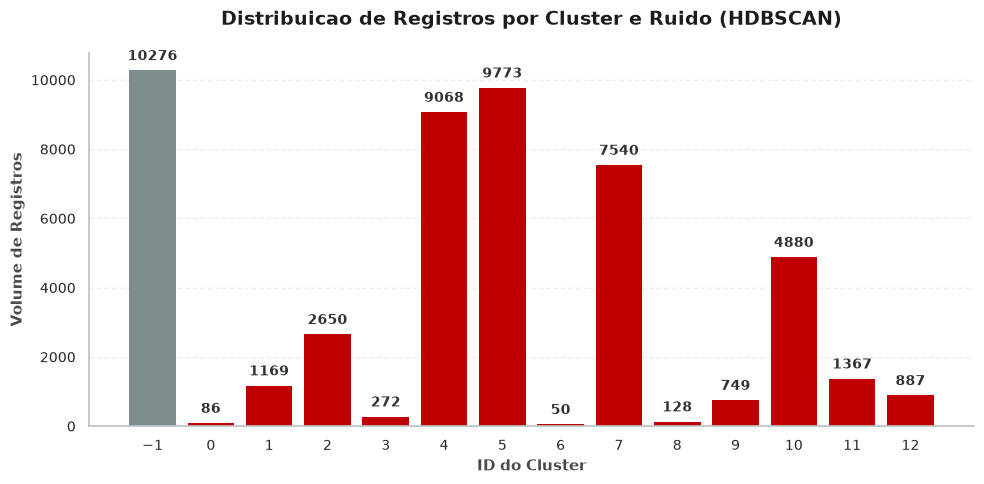

In [13]:
# Ajuste do modelo final com os melhores hiperparametros
hdb_final = hdbscan.HDBSCAN(
    min_cluster_size=50,
    min_samples=50,
    core_dist_n_jobs=-1,
)
labels_hdb = hdb_final.fit_predict(X_tratado)

# Atribuicao UNICA dos labels (corrigindo duplicacao anterior)
X_analise['Cluster_HDBSCAN'] = labels_hdb
df_umap['Cluster_HDBSCAN'] = labels_hdb

# Distribuicao de volume por cluster
plot_distribuicao_clusters(
    labels_hdb,
    titulo='Distribuicao de Registros por Cluster e Ruido (HDBSCAN)'
)


> **Desbalanceamento e Volume:** = Existe um forte desbalanceamente no volume das classses. Enquanto os clusters `4`, `5` e `7` concentram a maior parte dos dados, existem micro-clusters com volume extremamente baixo (como os clusters `6`, `0` e `8`, que possuem menos de 150 registros). Além disso, o ruído (cluster `-1`) representa uma parcela expressiva, com 10.276 registros (superior a qualquer cluster válido).
>
> Logicamente, o próximo passo **exige investigar  o significado desses agrupamentos e seus impactos na lógica de negócio**. Com base na plotagem do espaço 2D, será possível analisar a distribuição e o comportamento das classes principais em relação à sua proximidade espacial, validando se os micro-clusters isolados representam anomalias ou nichos muito específicos.

In [ ]:
# Paleta clara
cores_plotly = px.colors.qualitative.Alphabet
mapa_cores_hdb = {str(i): cores_plotly[i % len(cores_plotly)] for i in range(13)}
mapa_cores_hdb['-1'] = '#E5E7E9'

# Projecao 2D via UMAP com ruido destacado
plot_clusters_2d_plotly(
    df_umap,
    col_x='UMAP1', col_y='UMAP2',
    col_cluster='Cluster_HDBSCAN',
    mapa_cores=mapa_cores_hdb,
    titulo='Projecao 2D (UMAP): Clusters de Densidade vs Ruido (HDBSCAN)'
)

> ### Validacao Topologica do HDBSCAN
>
> - **Observacao Principal:** O HDBSCAN respeita perfeitamente as ilhas topologicas reveladas pelo UMAP, sem fatiar artificialmente os agrupamentos naturais como o K-Means fazia. 
> 
> O ruido (**21.02% da base, em cinza claro**) isola combinacoes atipicas de preco, estadia minima e localizacao que nao se encaixam em nenhum perfil denso.
>
> *A transicao de `K-Means para HDBSCAN representa um salto qualitativo na segmentacao`: saimos de 8 clusters esfericos forcados para **13 clusters puros + 1 grupo de ruido estruturado**, onde cada grupo representa uma persona de negocio distinta e acionavel.

___

## 5.0 Perfilamento Final e Mapeamento Geoespacial (HDBSCAN)

### 5.1 Perfil Quantitativo e Composicao por Distritos

In [15]:
perfil_hdb, distritos_hdb = gerar_perfil_clusters(X_analise, 'Cluster_HDBSCAN', bairros_dummies)

display(perfil_hdb)
display(distritos_hdb)

,Preco_Mediano,Custo_Estadia_Mediano,Distancia_Times_Square_Mediana,Reviews_Mes_Mediano,Taxa_Reviews_Mediana,Disponibilidade_Mediana,Volume_Oferta_Host,room_type_Moda,Tamanho_do_Cluster,Perc_Base (%)
Cluster_HDBSCAN,,,,,,,,,,
-1,145.0,495.0,0.06,0.60,7.14,156.0,193.0,2,10276,21.02
0,88.5,200.0,0.16,3.01,17.77,171.5,252.0,2,86,0.18
1,118.0,285.0,0.07,0.99,17.11,43.0,52.0,2,1169,2.39
2,58.0,100.0,0.09,0.89,12.27,93.0,180.0,1,2650,5.42
3,50.0,104.5,0.15,1.28,22.22,265.0,359.0,1,272,0.56
4,145.0,435.0,0.08,0.45,21.82,23.0,26.0,2,9068,18.55
5,63.0,150.0,0.08,0.33,14.92,20.0,30.0,1,9773,19.99
6,69.5,75.0,0.02,2.36,13.46,84.5,316.0,0,50,0.10
7,90.0,196.0,0.04,0.38,16.40,21.0,26.0,1,7540,15.42


,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island
Cluster_HDBSCAN,,,,
-1,12.3,59.0,18.0,2.5
0,0.0,0.0,0.0,37.2
1,0.0,0.0,100.0,0.0
2,0.0,0.0,100.0,0.0
3,0.0,0.0,0.0,30.5
4,100.0,0.0,0.0,0.0
5,100.0,0.0,0.0,0.0
6,0.0,100.0,0.0,0.0
7,0.0,100.0,0.0,0.0


### `Visão Geral dos Segmentos`

| Segmento Comercial | Clusters Envolvidos | Distrito Principal | Preço Mediano | Volume de Oferta do Host | Tipo de Imóvel Principal |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1. Tradicional de Brooklyn** | `4`, `5` | Brooklyn | $63 a $145 | Baixo (~26 a 30) | Inteiro / Quarto Compartilhado |
| **2. Acessível de Queens** | `1`, `2` | Queens | $58 a $118 | Médio (~52 a 180) | Inteiro / Quarto Compartilhado |
| **3. Mega-Gestores** | `8`, `9`, `12` | Manhattan | $150 a $229 | **Altíssimo** (9.8k a 105k) | Inteiro (Luxo) |
| **4. Turístico Central** | `6`, `7`, `10`, `11` | Manhattan | $69 a $200 | Baixo/Médio (~26 a 316) | Inteiro / Quarto |
| **5. Periférico** | `0`, `3` | Staten Island | $50 a $88 | Alto (~252 a 359) | Inteiro / Quarto |
| **6. Ruído** | `-1` | Espalhado | $145 | Variado | Misturado (Outliers) |


### 5.2 Visualizacao Geoespacial sobre Mapa Base (GeoPandas + CartoDB)

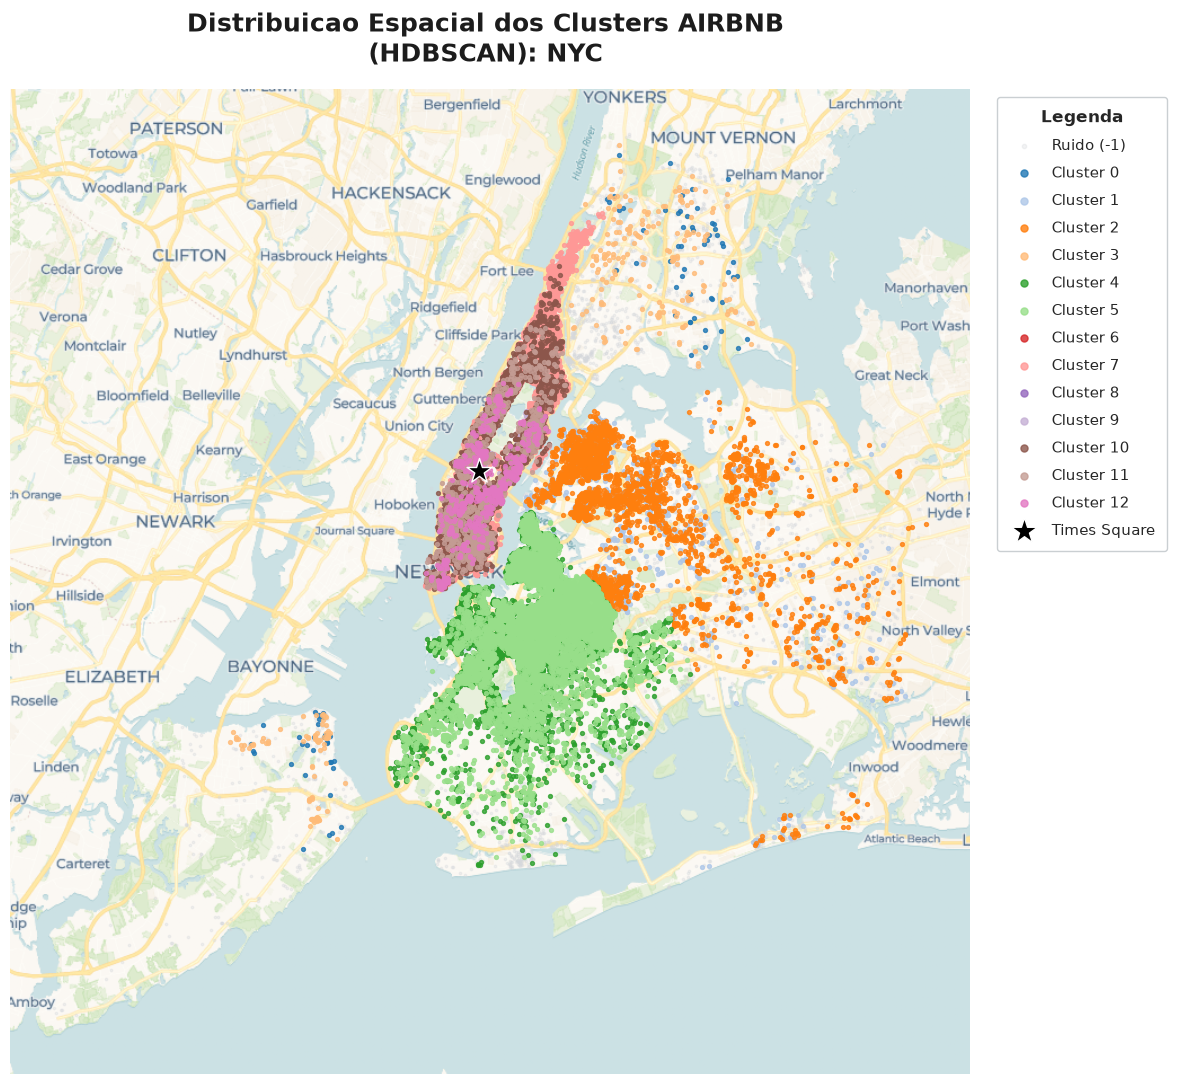

In [16]:
url_tiles_carto = (
    'https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png'
    '?key=cb1_4tpk_1_0dfd101156dab0c64eb2178d'
)

plot_mapa_clusters_nyc(
    X_geo=X_geo,
    labels=labels_hdb,
    titulo='Distribuicao Espacial dos Clusters AIRBNB \n(HDBSCAN): NYC ',
    url_tiles_carto=url_tiles_carto,
)


---

### Detalhamento Completo por Categoria

**1. Pequeno e Médio Anfitrião - Broonklyn - (Clusters `4` e `5`)**

* **Perfil:** O coração tradicional do Airbnb, representando **~38,5% da base**. 
* **Justificativa (Médias):** 100% localizados no Brooklyn. O preço mediano varia consideravelmente (de **$63** a **$145**), refletindo a divisão entre anfitriões que ofertam imóveis inteiros e os que alugam quartos. O volume de oferta por anfitrião é baixo (**26 a 30**), confirmando que são pessoas físicas ou pequenos investidores.


**2. O Mercado Acessível - Queens - (Clusters `1` e `2`)**
* **Perfil:** A porta de entrada para turistas econômicos, com foco em custo-benefício.
* **Justificativa (Médias):** 100% localizados em Queens. Os preços medianos são os mais baixos da base (**$58 a $118**). Os anfitriões possuem um volume moderado de gestão (**52 a 180** anúncios), indicando que já começam a operar em uma escala um pouco maior que o tradicional, mas com foco em preços agressivos.

**3.Mega Gestores e Imobiliárias - Manhattan - (Clusters `8`, `9` e `12`)**
* **Perfil:** A face corporativa da plataforma. Operações de escala industrial (fundos ou redes de imobiliárias).
* **Justificativa (Médias):** 100% localizados em Manhattan. Apresentam os maiores preços medianos (**$150 a $229**), focados em imóveis inteiros de luxo. O grande diferencial são os volumes de oferta absurdos, variando de **9.831 até 105.621** imóveis por anfitrião. Este é o grupo que o K-Means falhava em isolar.

**4. O Foco Turístico Central - Manhattan - (Clusters `6`, `7`, `10` e `11`)**
* **Perfil:** O epicentro do turismo, focado em giro rápido e alta rotatividade.
* **Justificativa (Médias):** Localizados em Manhattan, a uma distância média mínima da Times Square (entre 0.02 e 0.04). Apresenta polarização: mistura quartos mais baratos (**$69 a $90**) com imóveis inteiros premium (**$180 a $200**). O volume do anfitrião varia bastante (de 26 até 316).

**5. A Periferia - Staten Island - (Clusters `0` e `3`)**
* **Perfil:** Anfitriões que jogam o jogo do longo prazo e fora do eixo principal.
* **Justificativa (Médias):** Concentrados principalmente em Staten Island (37,2% e 30,5% dos clusters). Preços mais baixos (**$50 a $88**). Estes anfitriões possuem uma carteira de imóveis considerável (**252 a 359** anúncios) e focam em estadias mais longas.

**6. O Ruído Estruturado (Cluster `-1`)**
* **Perfil:** Anomalias e *outliers* que não pertencem a nenhuma densidade natural.
* **Justificativa (Médias):** Representa **21,02% da base** (10.276 registros). Espalhado por todos os distritos (mas com 59% em Manhattan). Possui um preço mediano alto (**$145**). O algoritmo agiu corretamente ao isolar esses dados (que podem ser erros de cadastro, fraudes ou imóveis ultra-específicos) para que não contaminassem a média dos clusters principais.

--
